# 004. Cubic anharmonicity in the 1D configurational coordinate model by perturbation theory

In Tutorial 002 each potential energy surface (PES) of the 1D configurational coordinate diagram (1D CCD) was a parabola,
and the Franck-Condon integrals $F_{ij}$ were those of two displaced harmonic oscillators. Real PESs are anharmonic. The
leading correction beyond the parabola is a cubic term,

$$V(Q) = a\,(Q - Q_0)^2 + b\,(Q - Q_0)^3 + c,$$

and if $b$ is small it can be treated by **first-order perturbation theory**: the harmonic eigenfunctions are corrected
analytically, and $F_{ij}$ is computed between the corrected states. This keeps the harmonic frequencies and Huang-Rhys
factors of Tutorial 002 and adds the effect of the cubic term on the wavefunctions at almost no cost.

This notebook shows

1. how to fit the cubic coefficient $b$ to the DFT images,
2. how strong the anharmonicity is (the dimensionless strength $\xi$) and up to which level the correction is reliable,
3. the corrected wavefunctions, compared with the harmonic ones and with the exact eigenstates of the cubic potential,
4. the Franck-Condon integrals and the vibrational overlap function (VOF) with the correction, and how much of the exact
   cubic effect it captures,
5. **the regime of validity**: a scan of $b$, a universal criterion, and an example (NV$^-$ in MgO) where it fails.

A **supplementary section** at the end derives the correction: the matrix elements of $Q^3$, the corrected
wavefunctions, the energy shifts, and the three conditions that define the regime of validity, each checked numerically.

We use the NV$^-$ center in diamond of Tutorial 002 (emission $^3E \rightarrow {}^3A_2$).

## 1. The 1D CCD and the cubic fits

In [1]:
import os

import numpy as np
import matplotlib.pyplot as plt
from scipy import constants

from pypl.config_coord_1d_solver import config_coord_1d_solver
from pypl.config_coord_1d_potential import config_coord_1d_potential
from pypl.config_coord_1d_vof_solver import config_coord_1d_vof_solver, grid_spacing, KINETIC
from pypl.utils import parse_atoms_qexml, parse_total_energy_qexml, parse_west_summary

plt.rcParams.update({"font.size": 12})
blue, red, gray = "#4285F4", "#DB4437", "0.35"
SUB = config_coord_1d_vof_solver

The CCD is built exactly as in Tutorial 002: $\Delta Q$ from the two relaxed structures, total energies of the
interpolated images, and parabolas fitted near each minimum (GS: images 1-5, ES: images 5-11). `config_coord_1d_potential`
does the fit and gives the phonon energy with the same expression as Tutorial 002.

In [2]:
data = "002_nv_diamond_1d_ccd"
mass_list = {"C": 12.0107, "N": 14.0067}
symbols, gs_coord, _ = parse_atoms_qexml(os.path.join(data, "gs_dft", "pwscf.xml"))
_, es_coord, _ = parse_atoms_qexml(os.path.join(data, "es_cdft", "pwscf.xml"))
masses = np.array([mass_list[s] for s in symbols])
delta_q = np.linalg.norm((es_coord - gs_coord) * masses[:, None] ** 0.5)

rel = np.linspace(-0.2, 1.2, 15)
images = {}
for state in ("gs", "es"):
    q, e = [], []
    for i in range(15):
        name = os.path.join(data, "%s_1d_ccd" % state, "Image-%d" % (i + 1), "pwscf.xml")
        if os.path.exists(name):
            q.append(delta_q * rel[i])
            e.append(parse_total_energy_qexml(name))
    images[state] = [np.array(q), np.array(e)]
e_ref = images["gs"][1].min()
for state in images:
    images[state][1] = images[state][1] - e_ref

center = {"gs": 0.0, "es": delta_q}
window = {"gs": slice(None, 5), "es": slice(4, None)}
parabola, cubic, phonon = {}, {}, {}
for state in ("gs", "es"):
    q, e = images[state]
    parabola[state] = config_coord_1d_potential(q, e, q0=center[state])
    parabola[state].fit_parabola(window[state])
    phonon[state] = parabola[state].phonon_energy()
    # cubic: a fixed to the parabola (same hbar*omega), b and c fitted to every image
    cubic[state] = config_coord_1d_potential(q, e, q0=center[state])
    cubic[state].fit_cubic(curvature=parabola[state].params["a"])

print("Delta Q = %.6f amu^0.5 A" % delta_q)
for state in ("gs", "es"):
    p = cubic[state].params
    print("%s: hbar w = %.5f meV | a = %.6f eV/(amu A^2) (fixed), b = %+.6f eV/(amu^1.5 A^3), turnover at Q = %+.1f | "
          "rms over all images: parabola %.2f meV, cubic %.2f meV"
          % (state.upper(), phonon[state], p["a"], p["b"], p["turnover"],
             1e3 * parabola[state].rms(), 1e3 * cubic[state].rms()))

Delta Q = 0.695732 amu^0.5 A
GS: hbar w = 59.08890 meV | a = 0.417627 eV/(amu A^2) (fixed), b = +0.009164 eV/(amu^1.5 A^3), turnover at Q = -30.4 | rms over all images: parabola 2.11 meV, cubic 0.16 meV
ES: hbar w = 64.31191 meV | a = 0.494721 eV/(amu A^2) (fixed), b = -0.012655 eV/(amu^1.5 A^3), turnover at Q = +26.8 | rms over all images: parabola 0.84 meV, cubic 0.16 meV


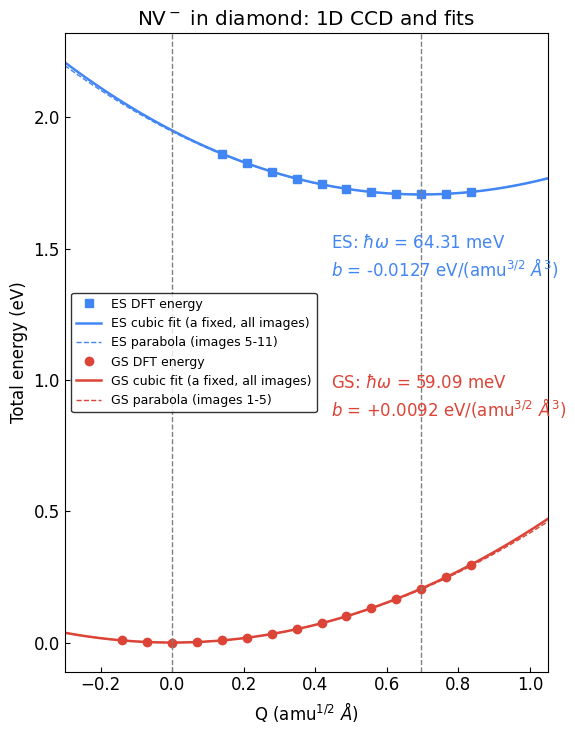

In [3]:
fig, ax = plt.subplots(figsize=(6, 7.5))
x = np.linspace(-0.3, 1.05, 500)
for state, color, marker, label in (("es", blue, "s", "ES"), ("gs", red, "o", "GS")):
    q, e = images[state]
    used = parabola[state].index
    ax.plot(q, e, marker, color=color, ms=6, ls="", label="%s DFT energy" % label)
    ax.plot(x, cubic[state](x), color=color, lw=1.8, label="%s cubic fit (a fixed, all images)" % label)
    ax.plot(x, parabola[state](x), color=color, lw=1.0, ls="--", label="%s parabola (images %d-%d)" % (label, used[0] + 1, used[-1] + 1))
    ax.text(0.55, 0.40 if state == "gs" else 0.62,
            "%s: $\\hbar\\omega$ = %.2f meV\n$b$ = %+.4f eV/(amu$^{3/2}$ $\\AA^3$)" % (label, phonon[state], cubic[state].params["b"]),
            color=color, transform=ax.transAxes)
for xv in (0.0, delta_q):
    ax.axvline(xv, color="gray", ls="--", lw=1)
ax.set_xlim(-0.3, 1.05)
ax.set_xlabel(r"Q (amu$^{1/2}$ $\AA$)")
ax.set_ylabel("Total energy (eV)")
ax.set_title(r"NV$^-$ in diamond: 1D CCD and fits")
ax.legend(fontsize=9, loc="center left", edgecolor="black")
ax.tick_params(direction="in")
plt.tight_layout()
plt.show()

Fixing $a$ to the parabola's curvature makes the unperturbed Hamiltonian exactly the harmonic one of Tutorial 002, so
the perturbation is the cubic term alone. Only $b$ and $c$ are fitted, to every image. (Fitting $a$ as well,
`fit_cubic()` without `curvature`, moves a small $(a_\mathrm{fit} - a)Q^2$ into neither part.) A cubic has a maximum,
the *turnover*, at $Q_0 - 2a/3b$; beyond it $V \to -\infty$. Here it lies tens of amu$^{1/2}$ Å away, far outside
anything the vibrational states reach.

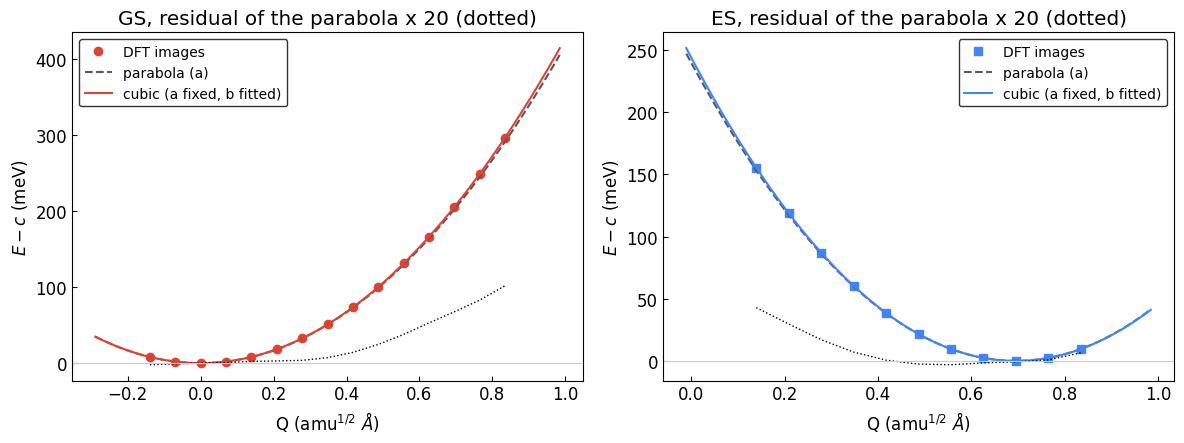

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, state, color, marker in ((axes[0], "gs", red, "o"), (axes[1], "es", blue, "s")):
    q, e = images[state]
    x = np.linspace(q.min() - 0.15, q.max() + 0.15, 400)
    ax.plot(q, 1e3 * (e - cubic[state].params["c"]), marker, color=color, ms=6, ls="", label="DFT images")
    ax.plot(x, 1e3 * (parabola[state](x) - cubic[state].params["c"]), color=gray, ls="--", label="parabola (a)")
    ax.plot(x, 1e3 * (cubic[state](x) - cubic[state].params["c"]), color=color, label="cubic (a fixed, b fitted)")
    ax.set_title("%s, residual of the parabola x 20 (dotted)" % state.upper())
    ax.plot(q, 20e3 * (e - parabola[state](q)), ":", color="k", lw=1)
    ax.axhline(0, color="0.8", lw=0.8)
    ax.set_xlabel(r"Q (amu$^{1/2}$ $\AA$)")
    ax.set_ylabel(r"$E - c$ (meV)")
    ax.legend(fontsize=10, edgecolor="black")
    ax.tick_params(direction="in")
plt.tight_layout()
plt.show()

On the scale of the CCD the parabola and the cubic are indistinguishable. Zooming in on each well (energies relative to
$c$, and the parabola residual magnified 20 times, dotted) shows the difference: the images are close to harmonic, the
residual of the parabola is a few meV, and the cubic picks up its odd part. NV$^-$ in diamond is therefore a weakly anharmonic case, the regime perturbation theory is meant for.

## 2. Strength of the anharmonicity and the reliable levels

In units of the oscillator's zero-point length $\ell = \sqrt{\hbar/2\Omega}$ and of $\hbar\Omega$, the cubic term has the
dimensionless strength

$$\xi = \frac{b\,\ell^3}{\hbar\Omega} = \frac{b}{\hbar\Omega}\left(\frac{\hbar}{2\Omega}\right)^{3/2}.$$

First-order perturbation theory mixes each harmonic state $|n\rangle$ with $|n\pm1\rangle$ and $|n\pm3\rangle$
(supplementary S2). The largest mixing coefficient is

$$c_{n+1} = -3\,\xi\,(n+1)^{3/2},$$

and it **grows with $n$**: higher levels reach further out, where $bQ^3$ is larger, while the energy gap stays
$\hbar\Omega$. The correction is reliable while $3|\xi|(n+1)^{3/2} \lesssim 0.1$ (the neglected second-order terms are
then $\lesssim 1\%$), which defines the highest reliable level $n_\mathrm{valid}$.

GS: xi = +1.032e-03, n_valid = 9 (mixing reaches 1.44 at n = 59)
ES: xi = -1.153e-03, n_valid = 8 (mixing reaches 1.61 at n = 59)


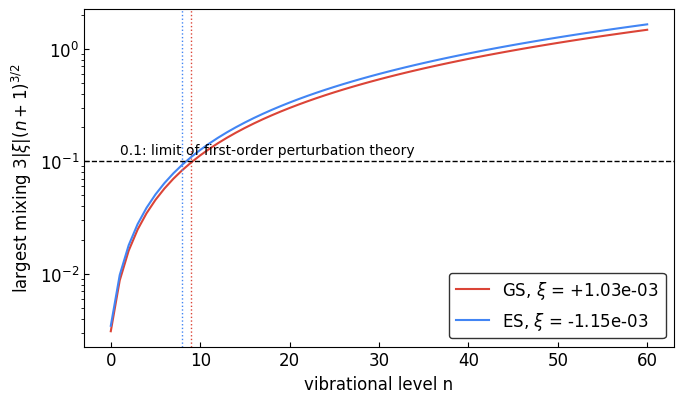

In [5]:
xi = {s: SUB.anharmonic_strength(cubic[s].params["b"], phonon[s]) for s in ("gs", "es")}
n = np.arange(0, 61)
fig, ax = plt.subplots(figsize=(7, 4.2))
for s, color in (("gs", red), ("es", blue)):
    mixing = 3 * abs(xi[s]) * (n + 1) ** 1.5
    n_valid = int(np.sum(mixing <= 0.1)) - 1
    print("%s: xi = %+.3e, n_valid = %d (mixing reaches %.2f at n = 59)" % (s.upper(), xi[s], n_valid, mixing[59]))
    ax.semilogy(n, mixing, color=color, label=r"%s, $\xi$ = %+.2e" % (s.upper(), xi[s]))
    ax.axvline(n_valid, color=color, ls=":", lw=1)
ax.axhline(0.1, color="k", ls="--", lw=1)
ax.text(1, 0.115, "0.1: limit of first-order perturbation theory", fontsize=10)
ax.set_xlabel("vibrational level n")
ax.set_ylabel(r"largest mixing $3|\xi|(n+1)^{3/2}$")
ax.legend(edgecolor="black")
ax.tick_params(direction="in")
plt.tight_layout()
plt.show()

$|\xi| \approx 10^{-3}$ is small, but the levels above $n \approx 8$-$9$ are already outside the strict first-order
regime. Whether that matters depends on which levels carry the intensity. At 5 K emission starts from $i = 0$ of the
excited state and ends mostly in final levels $j \lesssim 10$ (the Huang-Rhys factor is $S \approx 3.4$), so the correction
should be good where the intensity is. Sections 4 and 5 check this.

## 3. Corrected wavefunctions

`perturbed_wavefunction(q, n, omega, xi, center)` returns the first-order state

$$\tilde\psi_n = \psi_n + \xi\left[-3(n+1)^{3/2}\psi_{n+1} - \tfrac13\sqrt{(n+1)(n+2)(n+3)}\,\psi_{n+3}
+ 3n^{3/2}\psi_{n-1} + \tfrac13\sqrt{n(n-1)(n-2)}\,\psi_{n-3}\right],$$

a combination of harmonic functions with the coefficients of `cubic_correction_coefficients(n_levels, xi)`. We compare it
with the harmonic state $\psi_n$ and with the **exact** eigenstate of the same cubic potential, computed by
`solve_schrodinger_fd` (finite differences in a box well inside the turnover).

In [6]:
state = "gs"
omega, b_gs = phonon[state], cubic[state].params["b"]
q = np.linspace(-4.0, 4.0, 16001)
h = grid_spacing(q)
n_max = 40

E_exact, psi_exact = SUB.solve_schrodinger_fd(cubic[state](q), q, n_max + 1)
chi = SUB.harmonic_wavefunctions(q, n_max + 3, omega, center[state])
psi_pt = SUB.cubic_correction_coefficients(n_max + 1, xi[state]) @ chi
assert np.allclose(psi_pt[7], SUB.perturbed_wavefunction(q, 7, omega, xi[state], center[state]))


def infidelity(psi, ref):
    return 1.0 - abs(np.sum(psi * ref) * h) / np.sqrt(np.sum(psi**2) * h * np.sum(ref**2) * h)


print("GS: 1 - |<psi|psi_exact>| (normalized), and the norm of the first-order state")
print("  n    mixing    harmonic       first-order PT    <psi_pt|psi_pt> - 1")
for v in (0, 2, 5, 9, 15, 20, 30, 40):
    print("%3d   %7.3f   %10.2e   %14.2e   %16.2e" % (v, 3 * abs(xi[state]) * (v + 1) ** 1.5,
          infidelity(chi[v], psi_exact[v]), infidelity(psi_pt[v], psi_exact[v]), np.sum(psi_pt[v] ** 2) * h - 1))

GS: 1 - |<psi|psi_exact>| (normalized), and the norm of the first-order state
  n    mixing    harmonic       first-order PT    <psi_pt|psi_pt> - 1
  0     0.003     5.15e-06         2.49e-10           1.03e-05
  2     0.016     1.71e-04         2.78e-08           3.42e-04
  5     0.045     1.66e-03         9.03e-07           3.31e-03
  9     0.098     8.39e-03         1.54e-05           1.68e-02
 15     0.198     3.60e-02         2.49e-04           7.25e-02
 20     0.298     8.24e-02         1.32e-03           1.67e-01
 30     0.534     2.60e-01         1.49e-02           5.51e-01
 40     0.813     5.61e-01         7.87e-02           1.29e+00


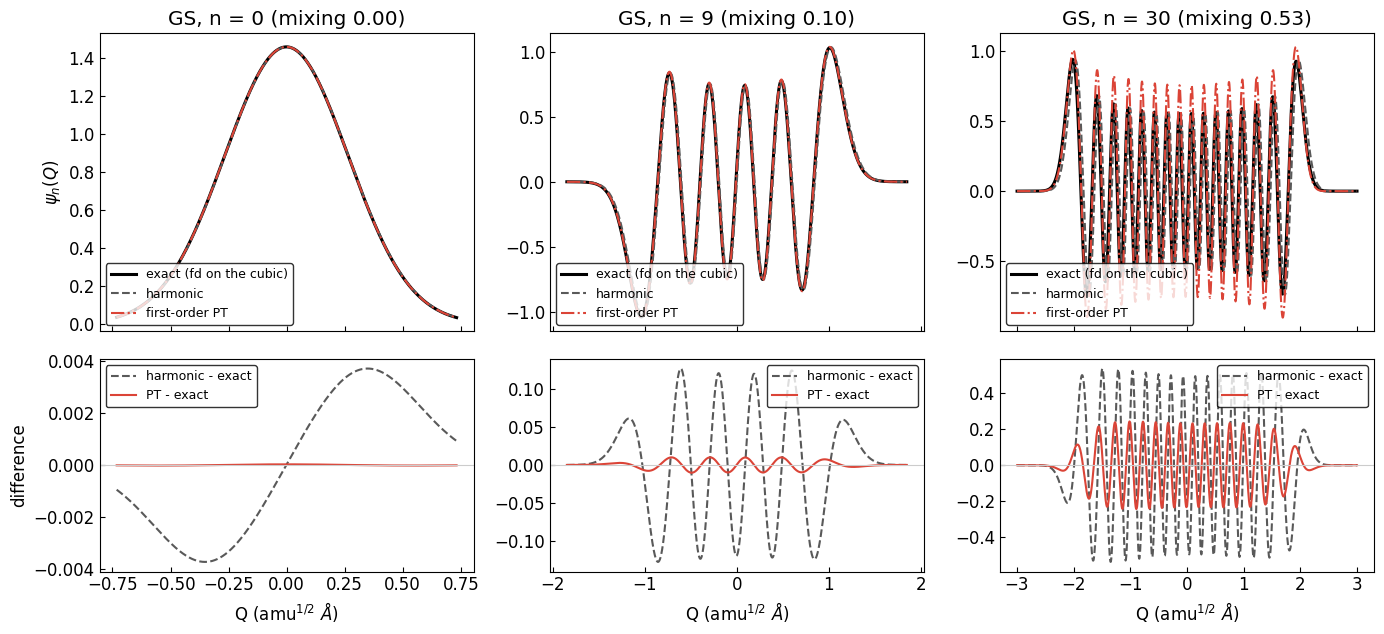

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(14, 6.5), sharex="col", gridspec_kw={"height_ratios": [1.4, 1]})
for k, v in enumerate((0, 9, 30)):
    lim = 1.25 * SUB.classical_turning_point(v, omega)
    sel = np.abs(q) < lim + 0.4
    ax = axes[0, k]
    ax.plot(q[sel], psi_exact[v][sel], color="k", lw=2.2, label="exact (fd on the cubic)")
    ax.plot(q[sel], chi[v][sel], color=gray, ls="--", label="harmonic")
    ax.plot(q[sel], psi_pt[v][sel], color=red, ls="-.", label="first-order PT")
    ax.set_title(r"GS, n = %d (mixing %.2f)" % (v, 3 * abs(xi[state]) * (v + 1) ** 1.5))
    ax.legend(fontsize=9, edgecolor="black", loc="lower left")
    ax = axes[1, k]
    ax.plot(q[sel], chi[v][sel] - psi_exact[v][sel], color=gray, ls="--", label="harmonic - exact")
    ax.plot(q[sel], psi_pt[v][sel] - psi_exact[v][sel], color=red, label="PT - exact")
    ax.axhline(0, color="0.8", lw=0.8)
    ax.set_xlabel(r"Q (amu$^{1/2}$ $\AA$)")
    ax.legend(fontsize=9, edgecolor="black")
for ax in axes.flat:
    ax.tick_params(direction="in")
axes[0, 0].set_ylabel(r"$\psi_n(Q)$")
axes[1, 0].set_ylabel("difference")
plt.tight_layout()
plt.show()

At $n = 0$ the correction removes almost all of the (already small) harmonic error, an improvement of four orders of
magnitude in the infidelity. At $n = 9$, the edge of the reliable range, PT is still about 500 times closer to the exact
state than the harmonic function. At $n = 30$ the mixing is about 0.5: the first-order state has visibly too much norm
(it is not renormalized) and its error is comparable to the effect it corrects.

## 4. Franck-Condon integrals and the VOF

`compute_franck_condon_integrals_cubic(ni, nf, b_i, b_f, q_i, q_f)` integrates $F_{ij} = \int \tilde\psi^{(i)}_i\,
\tilde\psi^{(f)}_j\,dQ$ between the corrected states of *both* wells, on the same quadrature grid as the Hermite route.
Emission is solved in the solver's mirrored frame (the final minimum at 0, the initial one at $-\Delta Q$), so both $b$
change sign internally; pass them as fitted, with the minima `q_i`, `q_f` on the CCD axis.

We compare three VOFs with the parameters of Tutorial 002 (50 ES $\times$ 60 GS levels, 5 K):

- **harmonic**: PyPL's Ruhoff recurrences on the parabolas, as in Tutorial 002;
- **first-order PT**: the cubic correction;
- **exact cubic**: `compute_franck_condon_integrals_fd` on the same two cubic potentials.

All three use `bulid_fc_lsp`, so the lines sit at the harmonic positions and the comparison isolates the effect on the
wavefunctions. (The first-order energy shift of a cubic term vanishes; the second-order shift is in supplementary S3.)

In [8]:
order_es, order_gs = 50, 60
lsp = dict(eneaxis=np.linspace(-200, 1200, 1401), temp=5, sigma=[8, 25], zpl_lorentzian=True, gamma=0.3)
w_es, w_gs = phonon["es"], phonon["gs"]
b_es, b_gs = cubic["es"].params["b"], cubic["gs"].params["b"]

harm = config_coord_1d_solver(w_es, w_gs, delta_q)
harm.compute_franck_condon_integrals(ni=order_es, nf=order_gs)
harm.bulid_fc_lsp(**lsp)

pt = SUB(w_es, w_gs, delta_q)
pt.compute_franck_condon_integrals_cubic(order_es, order_gs, b_es, b_gs, q_i=delta_q, q_f=0.0)
pt.bulid_fc_lsp(**lsp)

exact = SUB(w_es, w_gs, delta_q)
exact.compute_franck_condon_integrals_fd(order_es, order_gs, cubic["es"], cubic["gs"], q_i=delta_q, q_f=0.0)
exact.bulid_fc_lsp(**lsp)

print("\nxi in the solver frame: initial %+.3e, final %+.3e; n_valid: initial %d, final %d"
      % (pt.cubic_info["xi_i"], pt.cubic_info["xi_f"], pt.cubic_info["n_valid_i"], pt.cubic_info["n_valid_f"]))

Integral check: 1.0100972996226194
Integral check: 1.0102091413481957
Integral check: 1.0097556480366026

xi in the solver frame: initial +1.153e-03, final -1.032e-03; n_valid: initial 8, final 9


The warnings are the mixing criterion of section 2: the correction is applied to every level, but it is strictly
first order only up to $n_\mathrm{valid}$. They do not change the calculation. What matters is whether the intensity
comes from those levels:

weight of final levels above n_valid (j > 9): 0.17 %
max |VOF difference| / peak:  harmonic vs exact cubic = 3.38e-02   PT vs exact cubic = 3.14e-04
fraction of the cubic effect captured by first-order PT: 99.1 %
max |F_PT - F_exact|: i, j < 10: 6.1e-03   whole 50x60 matrix: 1.16


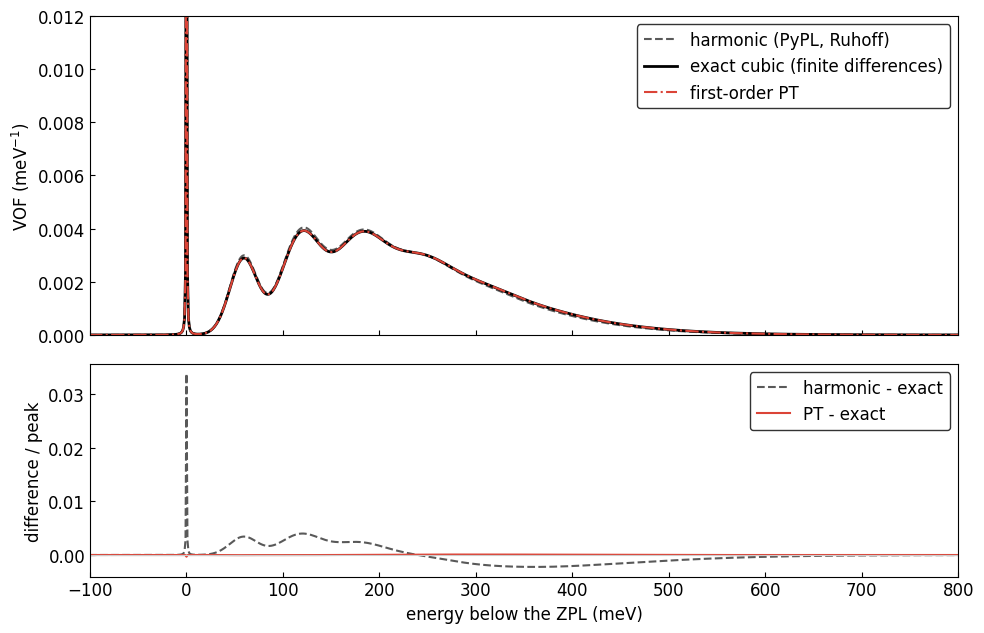

In [9]:
axis = lsp["eneaxis"]
peak = harm.fc_lineshape.max()
weights = harm.fc_ints[0] ** 2  # 5 K: only i = 0 is populated
print("weight of final levels above n_valid (j > %d): %.2f %%" % (pt.cubic_info["n_valid_f"],
      100 * weights[pt.cubic_info["n_valid_f"] + 1:].sum()))

effect = np.max(np.abs(exact.fc_lineshape - harm.fc_lineshape)) / peak
error = np.max(np.abs(pt.fc_lineshape - exact.fc_lineshape)) / peak
print("max |VOF difference| / peak:  harmonic vs exact cubic = %.2e   PT vs exact cubic = %.2e" % (effect, error))
print("fraction of the cubic effect captured by first-order PT: %.1f %%" % (100 * (1 - error / effect)))
dF = np.abs(pt.fc_ints - exact.fc_ints)
print("max |F_PT - F_exact|: i, j < 10: %.1e   whole %dx%d matrix: %.2f" % (dF[:10, :10].max(), order_es, order_gs, dF.max()))

fig, axes = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True, gridspec_kw={"height_ratios": [1.5, 1]})
axes[0].plot(axis, harm.fc_lineshape, color=gray, ls="--", label="harmonic (PyPL, Ruhoff)")
axes[0].plot(axis, exact.fc_lineshape, color="k", lw=2, label="exact cubic (finite differences)")
axes[0].plot(axis, pt.fc_lineshape, color=red, ls="-.", label="first-order PT")
axes[0].set_ylim(0, 0.012)
axes[0].set_ylabel(r"VOF (meV$^{-1}$)")
axes[0].legend(edgecolor="black")
axes[1].plot(axis, (harm.fc_lineshape - exact.fc_lineshape) / peak, color=gray, ls="--", label="harmonic - exact")
axes[1].plot(axis, (pt.fc_lineshape - exact.fc_lineshape) / peak, color=red, label="PT - exact")
axes[1].axhline(0, color="0.8", lw=0.8)
axes[1].set_ylabel("difference / peak")
axes[1].set_xlabel("energy below the ZPL (meV)")
axes[1].legend(edgecolor="black")
for ax in axes:
    ax.tick_params(direction="in")
    ax.set_xlim(-100, 800)
plt.tight_layout()
plt.show()

First-order PT reproduces the exact cubic VOF to a small fraction of the anharmonic effect, even though individual
$F_{ij}$ of the highest levels are badly wrong (they are outside the regime, and at 5 K they carry no weight). The PL
spectrum follows with `compute_spectrum`, exactly as in Tutorial 002:

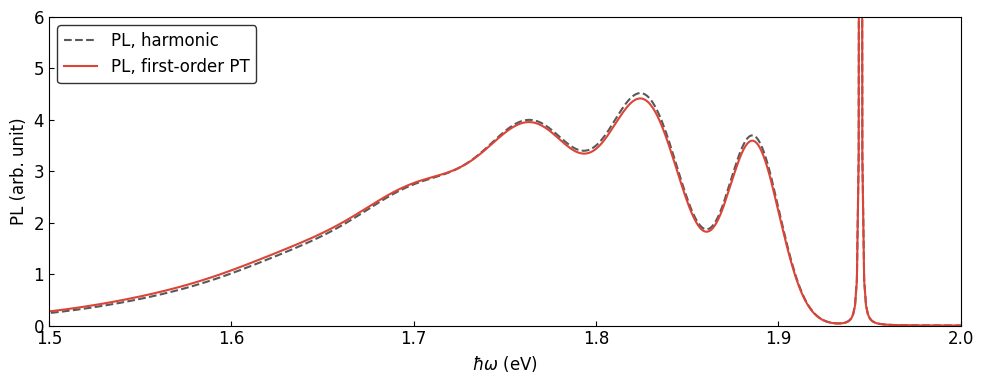

In [10]:
ezpl = 1945  # meV
fig, ax = plt.subplots(figsize=(10, 4))
for solver, label, style in ((harm, "harmonic", dict(color=gray, ls="--")), (pt, "first-order PT", dict(color=red))):
    e, s = solver.compute_spectrum(tdm=1.0, zpl=ezpl, spectrum_type="PL")
    ax.plot(e * 1e-3, s / (np.sum(s) * abs(e[1] - e[0])) * 1e3, label="PL, " + label, **style)
ax.set_xlim(1.5, 2.0)
ax.set_ylim(0, 6)
ax.set_xlabel(r"$\hbar\omega$ (eV)")
ax.set_ylabel("PL (arb. unit)")
ax.legend(edgecolor="black")
ax.tick_params(direction="in")
plt.tight_layout()
plt.show()

## 5. When is the perturbative correction valid?

Three tests, from the specific to the general.

### 5.1 Scaling with $b$

If the correction is right to first order, its error against the exact cubic must fall as $b^2$ when $b$ is scaled down,
while the anharmonic effect itself falls as $b$. We scale both fitted $b$ by $s$ and compare the $8 \times 8$ block of
$F_{ij}$ (12 levels per well, so the box stays well inside the turnover for every $s$).

log-log slope (s <= 1): PT error 1.99 (expected 2), anharmonic effect 1.00 (expected 1)
at the fitted b (s = 1): effect 5.43e-02, PT error 3.67e-03, ratio 15


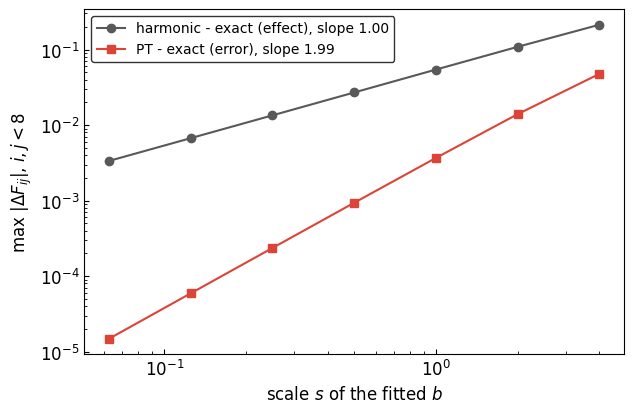

In [11]:
import contextlib, io

scales = np.array([1 / 16, 1 / 8, 1 / 4, 1 / 2, 1, 2, 4])
herm = SUB(w_es, w_gs, delta_q)
herm.compute_franck_condon_integrals_hermite(12, 12)
err_pt, effect = [], []
for s in scales:
    p_s = SUB(w_es, w_gs, delta_q)
    with contextlib.redirect_stdout(io.StringIO()):  # mixing warnings for the larger s
        p_s.compute_franck_condon_integrals_cubic(12, 12, s * b_es, s * b_gs, q_i=delta_q, q_f=0.0)
    wells = [lambda x, p=cubic[st].params, c=center[st]: p["a"] * (x - c) ** 2 + s * p["b"] * (x - c) ** 3
             for st in ("es", "gs")]
    e_s = SUB(w_es, w_gs, delta_q)
    e_s.compute_franck_condon_integrals_fd(12, 12, wells[0], wells[1], q_i=delta_q, q_f=0.0)
    err_pt.append(np.max(np.abs(p_s.fc_ints[:8, :8] - e_s.fc_ints[:8, :8])))
    effect.append(np.max(np.abs(herm.fc_ints[:8, :8] - e_s.fc_ints[:8, :8])))
err_pt, effect = np.array(err_pt), np.array(effect)
slope_err = np.polyfit(np.log(scales[:5]), np.log(err_pt[:5]), 1)[0]
slope_eff = np.polyfit(np.log(scales[:5]), np.log(effect[:5]), 1)[0]
print("log-log slope (s <= 1): PT error %.2f (expected 2), anharmonic effect %.2f (expected 1)" % (slope_err, slope_eff))
print("at the fitted b (s = 1): effect %.2e, PT error %.2e, ratio %.0f" % (effect[4], err_pt[4], effect[4] / err_pt[4]))

fig, ax = plt.subplots(figsize=(6.5, 4.3))
ax.loglog(scales, effect, "o-", color=gray, label="harmonic - exact (effect), slope %.2f" % slope_eff)
ax.loglog(scales, err_pt, "s-", color=red, label="PT - exact (error), slope %.2f" % slope_err)
ax.set_xlabel(r"scale $s$ of the fitted $b$")
ax.set_ylabel(r"max $|\Delta F_{ij}|$, $i, j < 8$")
ax.legend(fontsize=10, edgecolor="black")
ax.tick_params(direction="in", which="both")
plt.tight_layout()
plt.show()

The slopes are 2 and 1: the implementation is a correct first-order theory. At the fitted $b$ ($s = 1$) its error is
far below the effect it corrects (ratio printed above); as $s$ grows the two approach each other.

### 5.2 A universal criterion: the mixing parameter

Section 2 claimed that the quality of the correction for level $n$ depends only on $\mu_n = 3|\xi|(n+1)^{3/2}$, not on
$\xi$ and $n$ separately. We test it on model wells $V = aQ^2 + bQ^3$ with $\hbar\Omega = 60$ meV and $\xi$ from
$10^{-3}$ to $10^{-2}$, keeping only levels well below the barrier at the turnover (supplementary S4).

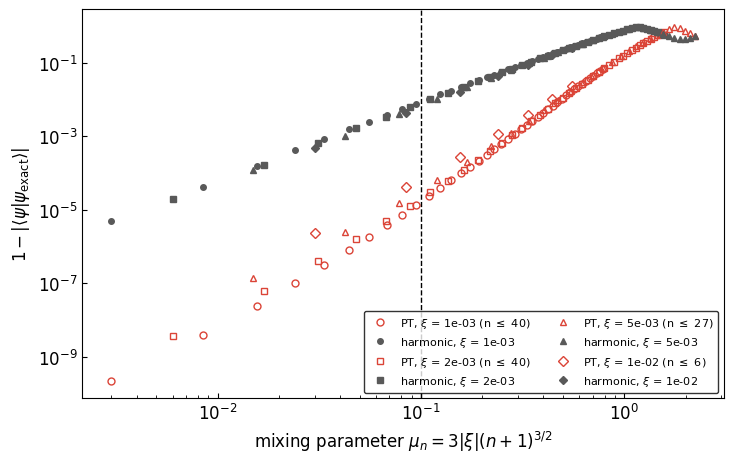

In [12]:
omega_m = 60.0
a_m = (omega_m * 1e-3) ** 2 / (4 * KINETIC)  # V = a Q^2 has hbar*omega = 2 sqrt(a * KINETIC)
alpha_m = SUB.harmonic_alpha(omega_m)
fig, ax = plt.subplots(figsize=(7.5, 4.8))
for xi_m, marker in ((1e-3, "o"), (2e-3, "s"), (5e-3, "^"), (1e-2, "D")):
    b_m = xi_m * omega_m * 1e-3 * (2 * alpha_m) ** 1.5
    q_turn = -2 * a_m / (3 * b_m)
    barrier_levels = 1 / (432 * xi_m**2)  # barrier height in units of hbar*omega (supplementary S4)
    n_top = int(min(40, 0.3 * barrier_levels))
    x_top = SUB.classical_turning_point(n_top, omega_m)
    x = np.linspace(max(q_turn * 0.85, -(x_top + 2.5)), x_top + 2.5, 12001)
    _, psi_x = SUB.solve_schrodinger_fd(a_m * x**2 + b_m * x**3, x, n_top + 1)
    chi_x = SUB.harmonic_wavefunctions(x, n_top + 3, omega_m)
    pt_x = SUB.cubic_correction_coefficients(n_top + 1, xi_m) @ chi_x
    hx = grid_spacing(x)
    fid = lambda f, g: 1 - abs(np.sum(f * g)) / np.sqrt(np.sum(f * f) * np.sum(g * g))
    levels = np.arange(n_top + 1)
    mu = 3 * xi_m * (levels + 1) ** 1.5
    ax.loglog(mu, [fid(pt_x[v], psi_x[v]) for v in levels], marker, color=red, ms=5, mfc="none",
              label=r"PT, $\xi$ = %.0e (n $\leq$ %d)" % (xi_m, n_top))
    ax.loglog(mu, [fid(chi_x[v], psi_x[v]) for v in levels], marker, color=gray, ms=4,
              label=r"harmonic, $\xi$ = %.0e" % xi_m)
ax.axvline(0.1, color="k", ls="--", lw=1)
ax.set_xlabel(r"mixing parameter $\mu_n = 3|\xi|(n+1)^{3/2}$")
ax.set_ylabel(r"$1 - |\langle \psi | \psi_\mathrm{exact} \rangle|$")
ax.legend(fontsize=8, ncol=2, edgecolor="black")
ax.tick_params(direction="in", which="both")
plt.tight_layout()
plt.show()

All $\xi$ fall on nearly one curve (the strongest, $\xi = 10^{-2}$, sits slightly above it, because its few levels
already feel the nearby barrier): the infidelity of the harmonic state grows as $\mu^2$, that of the first-order state
roughly as $\mu^3$, so the gain from PT is largest at small $\mu$. Below $\mu \approx 0.1$ the corrected states are within $\sim 10^{-5}$ of exact;
around $\mu \approx 1$ PT and harmonic are both poor. **The rule: first-order perturbation theory is valid for every
level that carries weight in the VOF having $\mu_n = 3|\xi|(n+1)^{3/2} \lesssim 0.1$**, with $\mu_n \lesssim 0.3$ as a
practical limit for a few-percent accuracy.

### 5.3 Where it fails: NV$^-$ in MgO

The $^3E \rightarrow {}^1A_1$ transition of NV$^-$ in MgO (Tutorial 003) has Huang-Rhys factors of 36-70, so the VOF is
carried by final levels $j \sim 30$-$60$, and its PESs are strongly anharmonic over $\Delta Q$. A cubic fitted over the
images between the two minima ($q = -0.10 \dots 1.15$, $a$ fixed to the parabolas of Tutorial 003):

In [13]:
import re

mgo = "003_nv_mgo_isc"
xml = lambda image: os.path.join(mgo, "qe", image, "data-file-schema.xml")
img_q = lambda name: float(re.fullmatch(r"Image_([+-]?\d+\.\d+)", name).group(1)) if name.startswith("Image_") else None
sym, c0, _ = parse_atoms_qexml(xml("Image_+0.00"))
_, c1, _ = parse_atoms_qexml(xml("Image_+1.00"))
m = np.array([{"N": 14.0067, "O": 15.999, "Mg": 24.305}[s] for s in sym])
dq_mgo = np.linalg.norm((c1 - c0) * m[:, None] ** 0.5)
e0 = min(parse_total_energy_qexml(xml(n)) for n in os.listdir(os.path.join(mgo, "qe")) if n != "Image_-1.00")


def load(run, root, exclude=()):
    pts = sorted((img_q(n), parse_total_energy_qexml(xml(n)) + parse_west_summary(os.path.join(mgo, run, n, "summary.json"))[root] - e0)
                 for n in os.listdir(os.path.join(mgo, run))
                 if img_q(n) is not None and n not in exclude
                 and os.path.exists(os.path.join(mgo, run, n, "summary.json")) and os.path.exists(xml(n)))
    return np.array(pts).T


print("NV- in MgO, cubic fitted to q = -0.10..1.15 with a fixed to the parabola of Tutorial 003:")
for name, run, root, excl, c, win in (("3E ", "sc", 0, (), 0.0, (-0.10, 0.45)), ("1A1", "sf", 3, ("Image_+2.00",), dq_mgo, (0.60, 1.15))):
    qi, ei = load(run, root, excl)
    Q = qi * dq_mgo
    par = config_coord_1d_potential(Q, ei, q0=c)
    par.fit_parabola(np.where((qi >= win[0] - 1e-9) & (qi <= win[1] + 1e-9))[0])
    cub = config_coord_1d_potential(Q, ei, q0=c)
    cub.fit_cubic(np.where((qi >= -0.10 - 1e-9) & (qi <= 1.15 + 1e-9))[0], curvature=par.params["a"])
    w = par.phonon_energy()
    x = SUB.anharmonic_strength(cub.params["b"], w)
    S = SUB.huang_rhys(w, dq_mgo)
    print("  %s: hbar w = %.2f meV, S = %.1f, xi = %+.3f, n_valid = %d, mixing at n = S: %.1f, turnover at Q = %+.2f "
          "(images span Q = %.2f..%.2f)" % (name, w, S, x, max(int((0.1 / (3 * abs(x))) ** (2 / 3) - 1), -1),
                                             3 * abs(x) * (S + 1) ** 1.5, cub.params["turnover"], Q.min(), Q.max()))

NV- in MgO, cubic fitted to q = -0.10..1.15 with a fixed to the parabola of Tutorial 003:
  3E : hbar w = 60.83 meV, S = 69.8, xi = -0.010, n_valid = 1, mixing at n = S: 17.1, turnover at Q = +3.24 (images span Q = -3.10..6.20)
  1A1: hbar w = 31.55 meV, S = 36.2, xi = +0.009, n_valid = 1, mixing at n = S: 6.1, turnover at Q = -1.70 (images span Q = -3.10..4.65)


Here $|\xi| \approx 0.01$, ten times the diamond value, the mixing at the levels that carry the intensity is far
above 1 ($n_\mathrm{valid} = 1$), and the turnover of
the cubic falls *inside* the range of the images, where the levels live: the cubic is not even a bound model of these
PESs. Perturbation theory does not apply; use the finite-difference route on a spline through all images, as in
Tutorial 003. **Tutorial 004a repeats this whole analysis for NV$^-$ in MgO.**

## 6. Summary

- The cubic correction keeps the harmonic frequencies and Huang-Rhys factors and corrects the vibrational states to first
  order in $\xi = b\ell^3/\hbar\Omega$. With `fit_cubic(curvature=a)` the unperturbed problem is exactly that of
  Tutorial 002.
- Its quality for level $n$ is set by $\mu_n = 3|\xi|(n+1)^{3/2}$; use it when the levels that carry the VOF have
  $\mu_n \lesssim 0.1$-$0.3$, i.e. small $\xi$, small Huang-Rhys factors and low temperature.
- For NV$^-$ in diamond ($\xi \approx 10^{-3}$, $S \approx 3.5$, 5 K) it captures nearly all of the exact cubic effect on the
  VOF. For NV$^-$ in MgO it is not applicable.
- The exact alternative for any potential is `compute_franck_condon_integrals_fd` (Tutorial 003 and Tutorial 005).

---

## Supplementary: derivation of the perturbative correction

### S1. Hamiltonian and units

In the mass-weighted coordinate $Q$ (amu$^{1/2}$ Å), with the minimum at $Q_0 = 0$,

$$\hat H = \hat H_0 + \hat H', \qquad \hat H_0 = \frac{\hat P^2}{2} + \frac{\Omega^2}{2}\hat Q^2, \qquad
\hat H' = b\,\hat Q^3,$$

where $a = \Omega^2/2$. With the ladder operators, $\hat Q = \ell\,(\hat a + \hat a^\dagger)$,
$\ell = \sqrt{\hbar/2\Omega}$, $\hat a|n\rangle = \sqrt n\,|n-1\rangle$ and $\hat a^\dagger|n\rangle = \sqrt{n+1}\,|n+1\rangle$,

$$\hat H' = b\,\ell^3\,(\hat a + \hat a^\dagger)^3 = \hbar\Omega\;\xi\,(\hat a + \hat a^\dagger)^3,
\qquad \xi = \frac{b\,\ell^3}{\hbar\Omega}.$$

So $\xi$ is the cubic term in units of $\hbar\Omega$ with $Q$ in units of the zero-point length; this is
`anharmonic_strength(b, omega)`.

### S2. Matrix elements and first-order wavefunctions

$(\hat a + \hat a^\dagger)^3$ has eight orderings. Acting on $|n\rangle$, each changes $n$ by $\pm1$ or $\pm3$. For
$m = n + 1$ three orderings contribute:

| ordering | amplitude |
| --- | --- |
| $\hat a^\dagger \hat a^\dagger \hat a$ | $n\sqrt{n+1}$ |
| $\hat a^\dagger \hat a \hat a^\dagger$ | $(n+1)\sqrt{n+1}$ |
| $\hat a \hat a^\dagger \hat a^\dagger$ | $(n+2)\sqrt{n+1}$ |
| **sum** | $3(n+1)^{3/2}$ |

and in the same way

$$\langle n+1|(\hat a+\hat a^\dagger)^3|n\rangle = 3(n+1)^{3/2}, \quad
\langle n+3|\cdots|n\rangle = \sqrt{(n+1)(n+2)(n+3)},$$
$$\langle n-1|\cdots|n\rangle = 3n^{3/2}, \quad \langle n-3|\cdots|n\rangle = \sqrt{n(n-1)(n-2)}.$$

The first-order state is $|\tilde n\rangle = |n\rangle + \sum_{m\neq n} c_m|m\rangle$ with
$c_m = \langle m|\hat H'|n\rangle / (E_n - E_m) = \xi\,\langle m|(\hat a+\hat a^\dagger)^3|n\rangle / (n - m)$:

| $m$ | $c_m$ |
| --- | --- |
| $n+1$ | $-3\xi(n+1)^{3/2}$ |
| $n+3$ | $-\tfrac13\xi\sqrt{(n+1)(n+2)(n+3)}$ |
| $n-1$ | $+3\xi n^{3/2}$ |
| $n-3$ | $+\tfrac13\xi\sqrt{n(n-1)(n-2)}$ |

which is the formula of section 3. Its norm is $\langle\tilde n|\tilde n\rangle = 1 + \sum_m c_m^2 = 1 + O(\xi^2 n^3)$; the
code does not renormalize unless asked (`normalize=True`). The Franck-Condon integrals between two corrected wells,

$$F_{ij} = \int \tilde\psi^{(i)}_i(Q)\,\tilde\psi^{(f)}_j(Q)\,dQ
= F^{(0)}_{ij} + \sum_{m} c^{(i)}_{m}(i)\,F^{(0)}_{mj} + \sum_{m} c^{(f)}_{m}(j)\,F^{(0)}_{im} + O(\xi^2),$$

are computed by quadrature of the corrected functions rather than from this expansion, which is equivalent to first
order. In the solver's frame the coordinate of an emission calculation is mirrored ($x = -(Q - Q_f)$), and $Q^3$ is odd,
so both $b$ change sign there.

The cell below checks the matrix elements and the coefficients against an explicit matrix representation of
$\hat a$, and the code's coefficients against $c_m = \xi\langle m|(\hat a+\hat a^\dagger)^3|n\rangle/(n-m)$.

In [14]:
N = 40
a_op = np.diag(np.sqrt(np.arange(1, N)), k=1)  # <n-1|a|n> = sqrt(n)
X3 = np.linalg.matrix_power(a_op + a_op.T, 3)
n_chk = np.arange(0, 30)
print("max |<n+1|X^3|n> - 3(n+1)^1.5|       = %.1e" % np.max(np.abs(X3[n_chk + 1, n_chk] - 3 * (n_chk + 1) ** 1.5)))
print("max |<n+3|X^3|n> - sqrt((n+1)(n+2)(n+3))| = %.1e" % np.max(np.abs(X3[n_chk + 3, n_chk] - np.sqrt((n_chk + 1) * (n_chk + 2) * (n_chk + 3)))))
print("diagonal <n|X^3|n> (first-order energy shift / xi hbar w): max %.1e" % np.max(np.abs(np.diag(X3)[:30])))

xi_t = 1e-3
C = SUB.cubic_correction_coefficients(25, xi_t)
C_ref = np.zeros_like(C)
for nn in range(25):
    C_ref[nn, nn] = 1.0
    for mm in range(C.shape[1]):
        if mm != nn:
            C_ref[nn, mm] = xi_t * X3[mm, nn] / (nn - mm)
print("max |cubic_correction_coefficients - xi <m|X^3|n> / (n - m)| = %.1e" % np.max(np.abs(C - C_ref)))

max |<n+1|X^3|n> - 3(n+1)^1.5|       = 5.7e-14
max |<n+3|X^3|n> - sqrt((n+1)(n+2)(n+3))| = 2.8e-14
diagonal <n|X^3|n> (first-order energy shift / xi hbar w): max 0.0e+00
max |cubic_correction_coefficients - xi <m|X^3|n> / (n - m)| = 1.1e-16


### S3. Energies

The first-order shift vanishes, $E^{(1)}_n = \hbar\Omega\,\xi\,\langle n|(\hat a+\hat a^\dagger)^3|n\rangle = 0$, because
$Q^3$ is odd. This is why the correction keeps the harmonic ladder and `bulid_fc_lsp` places the lines at the harmonic
positions. The leading shift is second order,

$$E^{(2)}_n = \sum_{m\neq n}\frac{|\langle m|\hat H'|n\rangle|^2}{(n-m)\hbar\Omega}
= \hbar\Omega\,\xi^2\left[\frac{9(n+1)^3}{-1} + \frac{(n+1)(n+2)(n+3)}{-3} + \frac{9n^3}{1} + \frac{n(n-1)(n-2)}{3}\right]
= -\hbar\Omega\,\xi^2\,(30n^2 + 30n + 11).$$

It is negative (a cubic softens the well) and grows as $n^2$; relative to the level spacing it is
$\sim 30\,\xi^2 n^2 \sim \mu_n^2/n$, so it is small whenever the wavefunction criterion holds. The cell checks it against
the exact finite-difference levels of a model well with $\xi = 5\times10^{-3}$:

In [15]:
xi_e = 5e-3
b_e = xi_e * omega_m * 1e-3 * (2 * alpha_m) ** 1.5
x = np.linspace(-2.5, 6.0, 16001)
E_fd, _ = SUB.solve_schrodinger_fd(a_m * x**2 + b_e * x**3, x, 16)
levels = np.arange(16)
shift_fd = E_fd * 1e3 - omega_m * (levels + 0.5)
shift_pt2 = -omega_m * xi_e**2 * (30 * levels**2 + 30 * levels + 11)
print("  n   exact shift (meV)   -hbar w xi^2 (30n^2 + 30n + 11) (meV)   ratio")
for v in (0, 1, 3, 6, 10, 15):
    print("%3d   %12.4f        %12.4f                          %6.3f" % (v, shift_fd[v], shift_pt2[v], shift_fd[v] / shift_pt2[v]))

  n   exact shift (meV)   -hbar w xi^2 (30n^2 + 30n + 11) (meV)   ratio
  0        -0.0165             -0.0165                           1.002
  1        -0.1069             -0.1065                           1.004
  3        -0.5613             -0.5565                           1.009
  6        -1.9366             -1.9065                           1.016
 10        -5.0950             -4.9665                           1.026
 15       -11.2384            -10.8165                           1.039


The second-order formula matches the exact shifts at low $n$ and drifts by a few percent at $n = 15$, where
$\mu_n \approx 1$ and higher orders appear. For the diamond wells ($|\xi| \approx 10^{-3}$) the shift of $n = 10$ is
$\approx -0.2$ meV, negligible next to the 8-25 meV broadening.

### S4. The regime of validity

Three conditions, all controlled by $\xi$ and $n$:

1. **Small mixing.** The neglected terms of the perturbation series are of order $c_m^2$. The largest coefficient is
   $|c_{n+1}| = \mu_n = 3|\xi|(n+1)^{3/2}$, so first order needs $\mu_n \ll 1$; $\mu_n \le 0.1$ keeps the error $\lesssim 1\%$.
   The highest reliable level is
   $$n_\mathrm{valid} = \left(\frac{0.1}{3|\xi|}\right)^{2/3} - 1,$$
   reported as `cubic_info["n_valid_i"]` / `["n_valid_f"]`; a warning is printed when the basis exceeds it.
2. **Small energy shift.** $|E^{(2)}_n| \ll \hbar\Omega$, i.e. $30\xi^2 n^2 \ll 1$. This is weaker than condition 1 for
   $n \geq 1$.
3. **Bound region.** The cubic has a maximum at the turnover $Q_t = -2a/3b$. With $a = \Omega^2/2$ and the definition of
   $\xi$,
   $$|Q_t| = \frac{\ell}{6|\xi|}, \qquad V(Q_t) - V(0) = \frac{4a^3}{27b^2} = \frac{\hbar\Omega}{432\,\xi^2}.$$
   The classical turning point of level $n$ is $\ell\sqrt{2(2n+1)}$, so the level must satisfy
   $6|\xi|\sqrt{2(2n+1)} \ll 1$ and lie far below the barrier, $n \ll 1/(432\xi^2)$. Beyond the turnover the potential has
   no bound states at all, and tunneling through the barrier is what perturbation theory cannot describe.

For $|\xi| = 10^{-3}$ the barrier holds about 2300 levels and condition 1 is the binding one ($n_\mathrm{valid} \approx 9$).
The numbers for the diamond fits:

In [16]:
for s in ("gs", "es"):
    p, x_s, w = cubic[s].params, xi[s], phonon[s]
    ell = np.sqrt(1 / (2 * SUB.harmonic_alpha(w)))
    barrier = p["a"] * (p["turnover"] - center[s]) ** 2 + p["b"] * (p["turnover"] - center[s]) ** 3
    print("%s: |Q_t - Q_0| = %.2f (l / 6|xi| = %.2f) amu^0.5 A; barrier = %.3f eV = %.0f hbar w (1 / 432 xi^2 = %.0f); "
          "n_valid = %.1f" % (s.upper(), abs(p["turnover"] - center[s]), ell / (6 * abs(x_s)), barrier,
                              barrier * 1e3 / w, 1 / (432 * x_s**2), (0.1 / (3 * abs(x_s))) ** (2 / 3) - 1))

GS: |Q_t - Q_0| = 30.38 (l / 6|xi| = 30.38) amu^0.5 A; barrier = 128.504 eV = 2175 hbar w (1 / 432 xi^2 = 2175); n_valid = 9.1
ES: |Q_t - Q_0| = 26.06 (l / 6|xi| = 26.06) amu^0.5 A; barrier = 112.012 eV = 1742 hbar w (1 / 432 xi^2 = 1742); n_valid = 8.4


The closed forms agree with the fitted cubics. Together with section 5, the practical rule is: **compute $\xi$ for each
well, find the levels that carry the VOF (at low temperature, $j$ up to a few times the Huang-Rhys factor of the final
state), and use the perturbative correction only if $3|\xi|(n+1)^{3/2} \lesssim 0.1$ for them**. Otherwise, solve the
potential exactly with `compute_franck_condon_integrals_fd`.